# Методология A/B-экспериментов на практике

Ноутбук проходит по всему жизненному циклу эксперимента, используя библиотеку
`abtest`, и на симуляциях показывает, что методы работают корректно.

**Содержание**
1. Синтетические данные
2. Планирование: размер выборки, мощность, MDE
3. Калибровка ошибки I рода (A/A)
4. Валидация: SRM и баланс ковариат
5. Анализ: доли, средние, бутстрап, непараметрика
6. CUPED - снижение дисперсии
7. Множественные сравнения
8. Подглядывание и sequential testing
9. Байесовский анализ
10. Автоматический вердикт


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from abtest import (power, datagen, srm, tests, cuped, multiple,
                    sequential, bayes, report, simulate)
np.random.seed(0)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True

## 1. Синтетические данные

Генератор создаёт эксперимент с *известным* истинным эффектом и пред-периодом -
это позволяет проверять корректность методов.

In [2]:
exp = datagen.generate_experiment(
    metric_type="continuous", n_users=20_000, baseline_mean=100, sd=25,
    true_effect=2.0, pre_correlation=0.8, seed=42,
)
print("Размеры групп:", exp.counts)
exp.data.head()

Размеры групп: {'control': 10062, 'treatment': 9938}


,user_id,group,pre_metric,metric,is_mobile,tenure_days
0,0,control,54.355695,39.782980,1,23.5
1,1,treatment,90.132790,73.319002,1,103.4
2,2,control,56.289977,73.421244,0,6.1
3,3,control,151.038470,139.745010,1,33.9
4,4,treatment,105.312280,92.539984,1,22.9


## 2. Планирование: размер выборки, мощность, MDE

Сколько наблюдений нужно, чтобы с мощностью 80% поймать относительный lift 5%
на базовой конверсии 10%?

In [3]:
ss = power.sample_size_proportion(0.10, 0.105, alpha=0.05, power=0.8)
print(f"n на группу = {ss.n_control:,}, всего = {ss.n_total:,}, "
      f"достигаемая мощность = {ss.power:.3f}")

# MDE: какой минимальный относительный эффект поймаем на 50k/группу?
mde = power.mde_proportion(0.10, 50_000, relative=True)
print(f"MDE при n=50k/группу: относит. {mde:.2%}")

n на группу = 57,763, всего = 115,526, достигаемая мощность = 0.800
MDE при n=50k/группу: относит. 5.38%


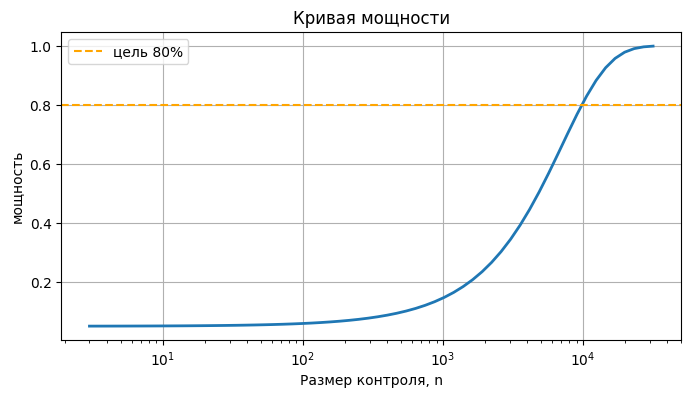

In [4]:
# Кривая мощности для непрерывной метрики
curve = power.power_curve_mean(effect=1.0, sd=25.0)
plt.plot(curve.x, curve.power, lw=2)
plt.axhline(0.8, ls="--", c="orange", label="цель 80%")
plt.xscale("log"); plt.xlabel(curve.xlabel); plt.ylabel("мощность")
plt.title("Кривая мощности"); plt.legend(); plt.show()

## 3. Калибровка ошибки I рода (A/A)

Под нулевой гипотезой доля значимых результатов должна быть около alpha. Проверяем
Монте-Карло.

FPR = 0.0506 (ожидается 0.05); 95% ДИ = [0.045; 0.057]


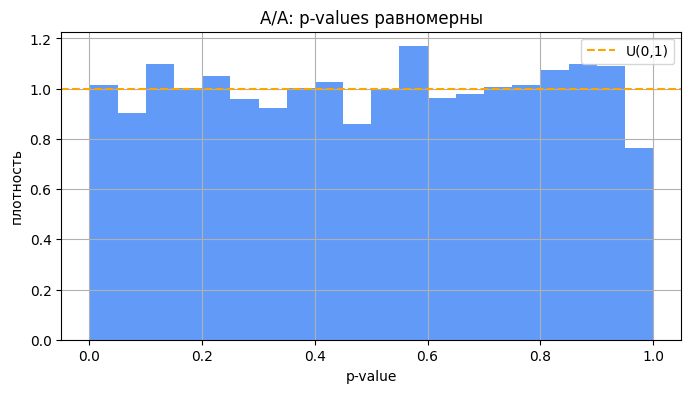

In [5]:
fpr = simulate.simulate_false_positive_rate(
    metric_type="conversion", n_sims=5000, n_per_group=5000, seed=0)
print(f"FPR = {fpr.fpr:.4f} (ожидается {fpr.alpha}); 95% ДИ = "
      f"[{fpr.ci[0]:.3f}; {fpr.ci[1]:.3f}]")
plt.hist(fpr.pvalues, bins=20, density=True, color="#3b82f6", alpha=0.8)
plt.axhline(1.0, ls="--", c="orange", label="U(0,1)")
plt.xlabel("p-value"); plt.ylabel("плотность")
plt.title("A/A: p-values равномерны"); plt.legend(); plt.show()

## 4. Валидация дизайна: SRM и баланс ковариат

SRM - сигнал поломки сплитования. Сравним чистый и заведомо поломанный сплит.

In [6]:
clean = datagen.generate_experiment(metric_type="conversion", n_users=40_000, seed=1)
broken = datagen.generate_experiment(metric_type="conversion", n_users=40_000,
                                     srm=True, srm_actual_share=0.46,
                                     covariate_imbalance=True, seed=1)
print("Чистый: ", srm.check_srm(clean.counts).summary)
print("Поломанный:", srm.check_srm(broken.counts).summary)

bal = srm.covariate_balance(broken.data, "group", ["is_mobile", "tenure_days"],
                            "control", "treatment")
bal

Чистый:  SRM не обнаружен: χ^2=0.292, p=0.5892 (порог 0.001)
Поломанный: SRM ОБНАРУЖЕН: χ^2=225.901, p=4.67e-51 (порог 0.001)


,covariate,type,effect_size,statistic,p_value,balanced
0,is_mobile,categorical,0.158877,1009.678864,1.413968e-221,False
1,tenure_days,numeric,0.928830,0.928830,0.000000e+00,False


## 5. Анализ результатов

Доли (z-тест), средние (Уэлч), бутстрап (BCa) и непараметрика (Манна-Уитни).

In [7]:
# Доли
r = tests.proportion_ztest(1000, 10_000, 1120, 10_000)
print("Доли:", r.summary)

# Средние на нашем непрерывном эксперименте
c, t = exp.group_arrays("metric")
w = tests.welch_ttest(c, t)
print("Уэлч:", w.summary)

boot = tests.bootstrap_mean_diff(c, t, n_boot=5000, method="bca", seed=0)
print("Бутстрап:", boot.summary)

mw = tests.mann_whitney(c, t)
print("Манна-Уитни:", mw.summary)

Доли: Δ=+0.0120 (95% ДИ [+0.0035; +0.0205]), относит. lift=+12.00%, p=0.005844
Уэлч: Δ=+1.7077 (95% ДИ [+1.0120; +2.4034]), t=4.812, df=19990.6, p=1.509e-06


Бутстрап: Δ=+1.7077 (bca, 95% ДИ [+1.0228; +2.4103])
Манна-Уитни: U=51845747.0, rank-biserial=+0.037, p=6.016e-06


## 6. CUPED - снижение дисперсии

Пред-период убирает предсказуемую часть дисперсии, поэтому доверительный интервал уже, а мощность выше.

In [8]:
pc, pt = exp.group_arrays("pre_metric")
cu = cuped.cuped_ttest(c, pc, t, pt)
print(cu.summary)
print(f"p-value: до = {cu.test_unadjusted.p_value:.3g} -> "
      f"после = {cu.test_adjusted.p_value:.3g}")

sim = simulate.simulate_cuped(correlation=0.7, n_sims=2000, seed=0)
print(f"Симуляция: мощность {sim.power_without:.3f} -> {sim.power_with:.3f}, "
      f"снижение дисперсии {sim.var_reduction_observed:.1%} (теория {sim.var_reduction_theoretical:.1%})")

θ=0.8011, ρ=+0.802, снижение дисперсии=64.3%; ДИ до=[+1.0120; +2.4034] -> после=[+1.2933; +2.1239]
p-value: до = 1.51e-06 -> после = 7.81e-16


Симуляция: мощность 0.169 -> 0.286, снижение дисперсии 49.0% (теория 49.0%)


## 7. Множественные сравнения

Несколько метрик, поэтому нужна поправка (Bonferroni для FWER, BH для FDR).

In [9]:
pvals = np.array([0.001, 0.012, 0.03, 0.048, 0.2])
bh = multiple.adjust_pvalues(pvals, method="benjamini-hochberg")
bonf = multiple.adjust_pvalues(pvals, method="bonferroni")
print("Исходные:  ", np.round(pvals, 4))
print("BH adj:    ", np.round(bh.adjusted, 4), "| значимых:", bh.n_significant)
print("Bonf adj:  ", np.round(bonf.adjusted, 4), "| значимых:", bonf.n_significant)

Исходные:   [0.001 0.012 0.03  0.048 0.2  ]
BH adj:     [0.005 0.03  0.05  0.06  0.2  ] | значимых: 3
Bonf adj:   [0.005 0.06  0.15  0.24  1.   ] | значимых: 1


## 8. Подглядывание и sequential testing

Наивная ежедневная проверка раздувает alpha; mSPRT и alpha-spending - нет.

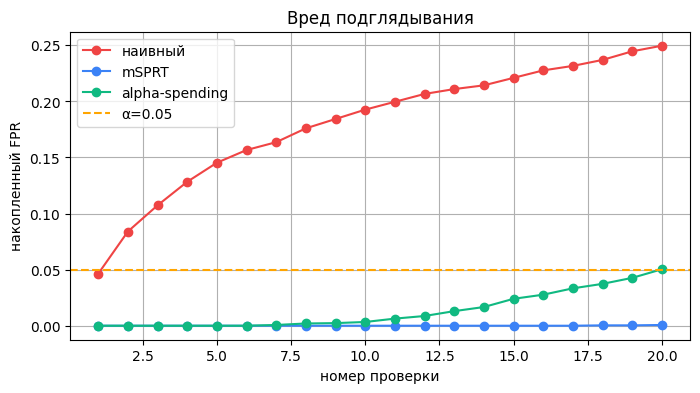

Итог: наивный=0.250, mSPRT=0.001, alpha-spending=0.050


In [10]:
pk = simulate.simulate_peeking(n_per_group=2000, n_looks=20, n_sims=3000, seed=0)
x = np.arange(1, pk.look_fractions.size + 1)
plt.plot(x, pk.cumulative_fpr_naive, "-o", c="#ef4444", label="наивный")
plt.plot(x, pk.cumulative_fpr_msprt, "-o", c="#3b82f6", label="mSPRT")
plt.plot(x, pk.cumulative_fpr_spending, "-o", c="#10b981", label="alpha-spending")
plt.axhline(0.05, ls="--", c="orange", label="α=0.05")
plt.xlabel("номер проверки"); plt.ylabel("накопленный FPR")
plt.title("Вред подглядывания"); plt.legend(); plt.show()
print(f"Итог: наивный={pk.cumulative_fpr_naive[-1]:.3f}, "
      f"mSPRT={pk.cumulative_fpr_msprt[-1]:.3f}, "
      f"alpha-spending={pk.cumulative_fpr_spending[-1]:.3f}")

In [11]:
# Границы O'Brien-Fleming
sp = sequential.alpha_spending_boundaries(np.array([0.25,0.5,0.75,1.0]),
                                          spending="obrien-fleming")
print(sp.summary)

obrien-fleming: z-границы = [3.918, 2.773, 2.300, 2.044] (α=0.05, 2-сторон.)


## 9. Байесовский анализ

Вероятность, что B лучше A, и ожидаемые потери.

In [12]:
b = bayes.beta_binomial(1000, 10_000, 1120, 10_000, seed=0)
print(b.summary)
print(f"95% ДИ относит. lift: [{b.lift_ci[0]:.2%}; {b.lift_ci[1]:.2%}]")

P(B>A)=99.7%, ожидаемые потери при выборе B=3.66e-06, lift=+12.08%; рекомендация: раскатывать B (ожидаемые потери ниже порога)
95% ДИ относит. lift: [3.34%; 21.39%]


## 10. Автоматический вердикт

Собираем всё в одно решение с предупреждениями.

In [13]:
verdict = report.interpret(w, practical_threshold=0.5,
                           srm_result=srm.check_srm(exp.counts))
print(verdict.text)

ВЕРДИКТ: Значимый положительный эффект

Рекомендация: Раскатывать вариант: эффект статистически и практически значим.

Эффект (абсолютный): +1.7077, 95% ДИ [+1.0120; +2.4034]
Относительный lift: +1.71%
p-value: 1.509e-06 (порог α=0.05)
Статистическая значимость: да
Практическая значимость: да


---
Полное описание методов - в `METHODOLOGY.md`. Интерактивные версии графиков - в
Streamlit-дашборде (`make dashboard`).